# Practical Aspects of Neural Networks — Part 2 of 2

**Last time (Part 1):** Business Case, Baseline Model, Orthogonalization

**Today (Part 2):**

- Gradient Checking (Gradient Approximation)
- Single Evaluation Metric
- Human-level Performance
- Multi-task Learning

# Picking Up Where We Left Off

In Part 1, we built a baseline neural network for Axis Bank's customer segmentation problem, and learned how to diagnose *why* a model underperforms using orthogonalization — which knob to turn for which symptom, and in what order to tune hyperparameters.

Today we go deeper into four more practical skills: proving that backpropagation itself is implemented correctly (gradient checking), picking an evaluation metric that cannot lie to you, knowing when a model is actually “good enough” to ship (human-level performance), and extending a classifier to problems with more than one correct label at a time (multi-task learning).

### Quick Recap: Rebuilding Where Part 1 Left Off

This notebook is self-contained, so before continuing we quickly re-run Part 1's pipeline: load the data, then build and train the same baseline model with the same random seeds. Running the cells below reproduces exactly the same `model` and training `history` we ended Part 1 with — nothing new to learn here, just re-arriving at where we left off. If you still have Part 1's notebook open with its runtime alive, you can skip straight to the **Gradient Checking** section below.

In [ ]:
!gdown 1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6

Downloading...
From: https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6
To: /content/customer_train.csv
100% 425k/425k [00:00<00:00, 140MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('customer_train.csv')
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
df.drop(columns=['Var_1', 'ID'], inplace=True)

df.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,A


In [ ]:
df.dropna(inplace=True)

df.isnull().sum()

,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,0
Spending_Score,0
Family_Size,0
Segmentation,0


**Encode the categorical features and the target:**

In [ ]:
# Store the class labels as integers 0..3  (A, B, C, D)
classes = sorted(df['Segmentation'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

y = df['Segmentation'].map(class_to_idx)
X = df.drop(columns=['Segmentation'])

print(classes, class_to_idx)

['A', 'B', 'C', 'D'] {'A': 0, 'B': 1, 'C': 2, 'D': 3}


In [ ]:
X = pd.get_dummies(X, columns=['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score'], dtype=float)

X.head()

,Age,Work_Experience,Family_Size,Gender_Female,Gender_Male,Ever_Married_No,Ever_Married_Yes,Graduated_No,Graduated_Yes,Profession_Artist,...,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Spending_Score_Average,Spending_Score_High,Spending_Score_Low
0,22,1.0,4.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,67,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,67,0.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5,56,0.0,2.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,32,1.0,3.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)

print('Train : ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test  : ', X_test.shape, y_test.shape)

Train :  (5441, 21) (5441,)
Validation: (605, 21) (605,)
Test  :  (672, 21) (672,)


In [ ]:
from sklearn.preprocessing import StandardScaler

X_val_df = X_val.copy()      # keep an unscaled copy of the validation rows, we will need it for error analysis later

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

**Define and initialize the baseline model:**

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# For Reproducibility
np.random.seed(42)
_ = torch.manual_seed(42)

In [ ]:
def create_baseline(in_features, n_classes=4):
    model = nn.Sequential(
        nn.Linear(in_features, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, n_classes),          # raw logits: no softmax here, nn.CrossEntropyLoss adds it
    )
    # Glorot (Xavier) initialization with zero biases
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.long)
y_val_t   = torch.tensor(y_val.values,   dtype=torch.long)
y_test_t  = torch.tensor(y_test.values,  dtype=torch.long)

model = create_baseline(X_train_t.shape[1])
print(model)

Sequential(
  (0): Linear(in_features=21, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=8, bias=True)
  (7): ReLU()
  (8): Linear(in_features=8, out_features=4, bias=True)
)


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

loss_fn = nn.CrossEntropyLoss()

def predict(model, X):
    # Returns the raw scores and the predicted class, with gradient tracking switched off
    model.eval()
    with torch.no_grad():
        logits = model(X)
    return logits, logits.argmax(dim=1)

def train_model(model, lr=1e-3, epochs=10, batch_size=128):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {k: [] for k in ["loss", "precision", "recall", "f1",
                               "val_loss", "val_precision", "val_recall", "val_f1"]}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()              # 1. clear the old gradients
            loss = loss_fn(model(xb), yb)      # 2. forward pass and loss
            loss.backward()                    # 3. backpropagation
            optimizer.step()                   # 4. update the weights

        # metrics on the full train and validation sets at the end of every epoch
        for prefix, X_, y_ in [("", X_train_t, y_train_t), ("val_", X_val_t, y_val_t)]:
            logits, pred = predict(model, X_)
            y_np, p_np = y_.numpy(), pred.numpy()
            history[prefix + "loss"].append(loss_fn(logits, y_).item())
            history[prefix + "precision"].append(precision_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "recall"].append(recall_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "f1"].append(f1_score(y_np, p_np, average="macro", zero_division=0))
    return history

def plot_history(history, metric, title=None):
    epochs = range(1, len(history[metric]) + 1)
    plt.plot(epochs, history[metric], label="train")
    plt.plot(epochs, history["val_" + metric], label="validation")
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.title(title or f"{metric} vs epochs")
    plt.show()

**Retrain the baseline (same seeds, same hyperparameters — this takes a few seconds):**

In [ ]:
torch.manual_seed(42)
model = create_baseline(X_train_t.shape[1])

history = train_model(model, lr=1e-3, epochs=10, batch_size=128)

# Gradient Checking

So far, we assumed that the training machinery itself works. But what if the loss refuses to go down even though we turned the right knobs? One possible reason is a bug inside backpropagation. How can we check that the gradients are correct?

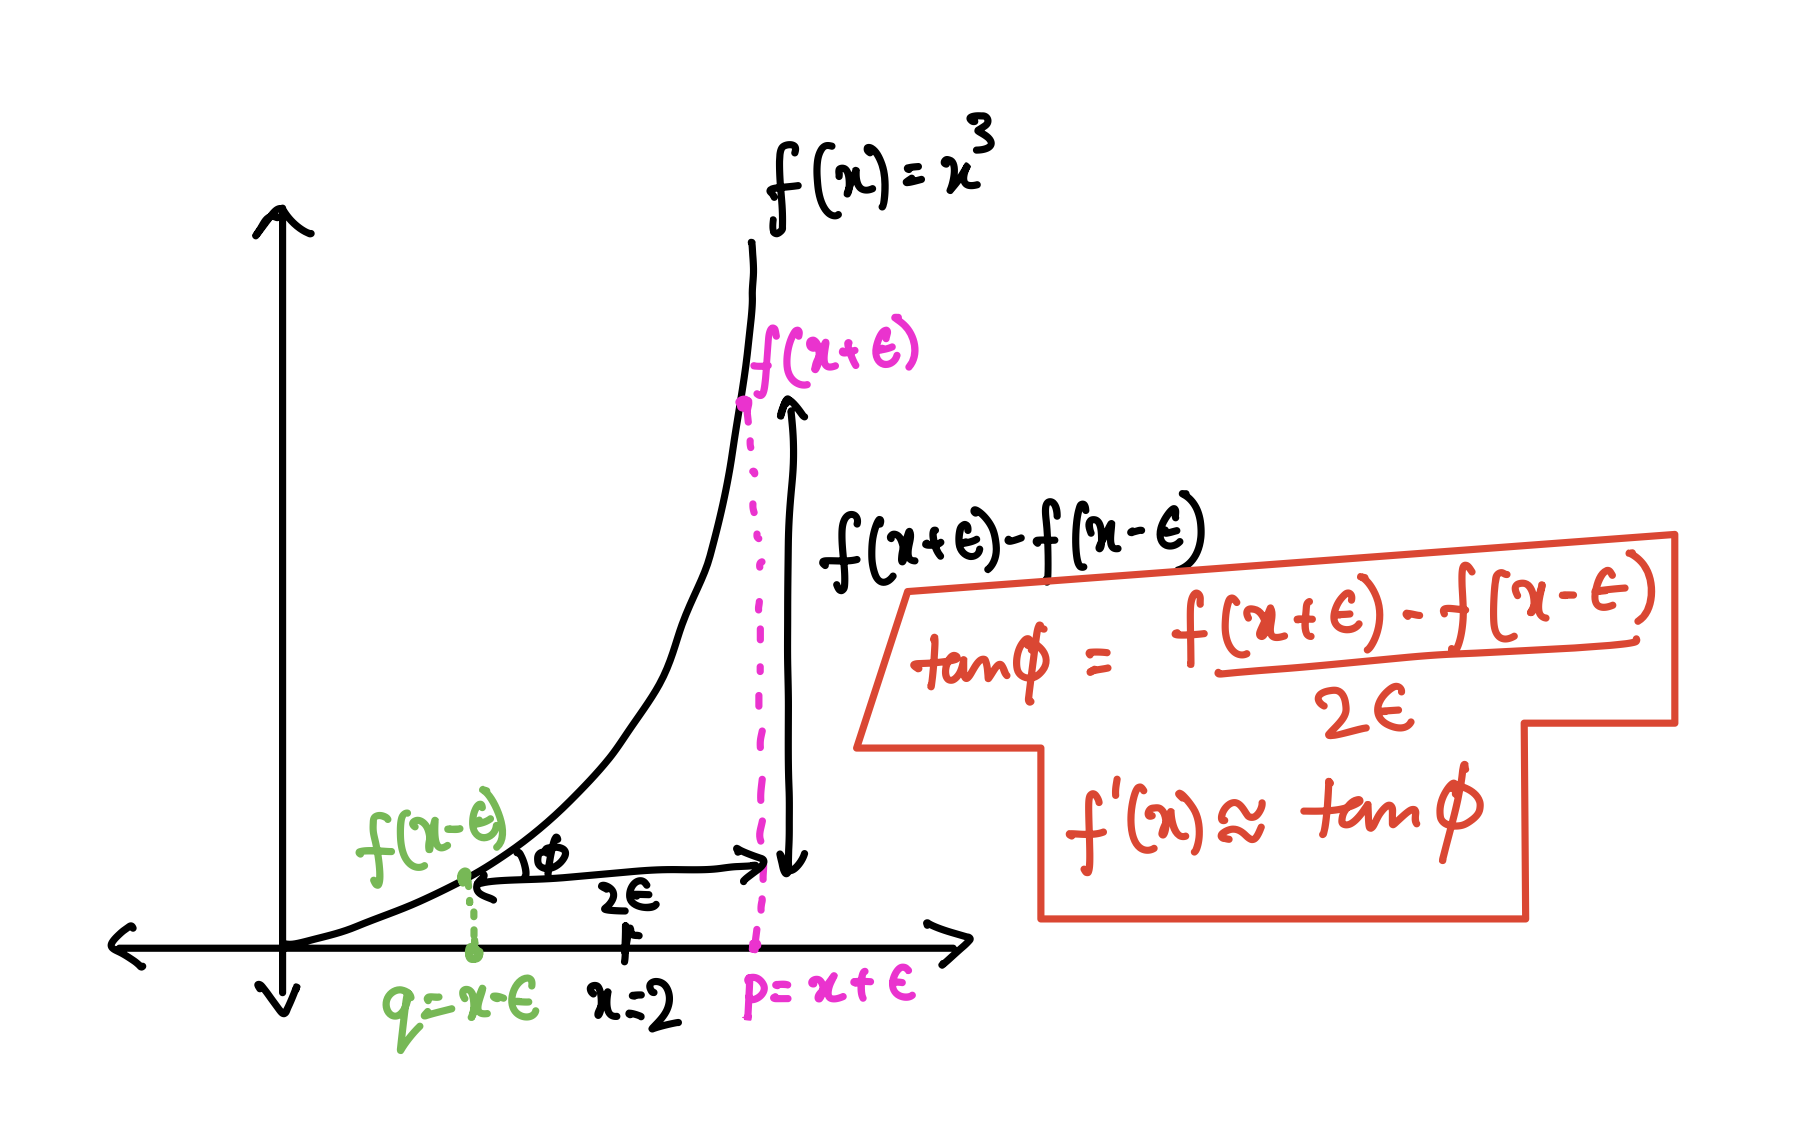

### Why Do We Need Gradient Checking?

A neural network is a black box, and that makes it hard to interpret. Sometimes, even after a series of sensible hyperparameter choices, the network does not perform well. One possible reason is that backpropagation computes wrong gradients because of a bug in the gradient calculation.

**Important:** In PyTorch, autograd computes the gradients of the built-in layers for us, so we rarely need gradient checking for them. It is most valuable when we write **custom layers, custom loss functions or a hand-written backward pass**, for example a new operation from a research paper. That is why PyTorch ships a ready-made tool for it, `torch.autograd.gradcheck`.

### How to Check if the Gradients from Backpropagation Are Correct?

If we can **approximate** the gradient numerically, we can compare:

Approximate gradient value $=$ Actual gradient value

### How to Calculate the Approximate Gradient Value?

Let's take an example. Suppose we have the function $f(x) = x^3$, and the graph looks like the snapshot above.

Take two points $p, q$ around $x=2$, such that:
- $p = x + \epsilon$
- $q = x - \epsilon$
- where $\epsilon = 0.01$

Consider the triangle created by the points $p$ and $q$:
- The base of the triangle is $p - q = (x+\epsilon) - (x-\epsilon) = 2\epsilon$
- The height of the triangle is $f(p) - f(q) = f(x+\epsilon) - f(x-\epsilon)$

Recall from calculus that the derivative $f'(x)$ is the slope, which is $\tan$ of the angle of the triangle created by the points on the function:
- $\tan = \frac{f(x+\epsilon) - f(x-\epsilon)}{2\epsilon}$

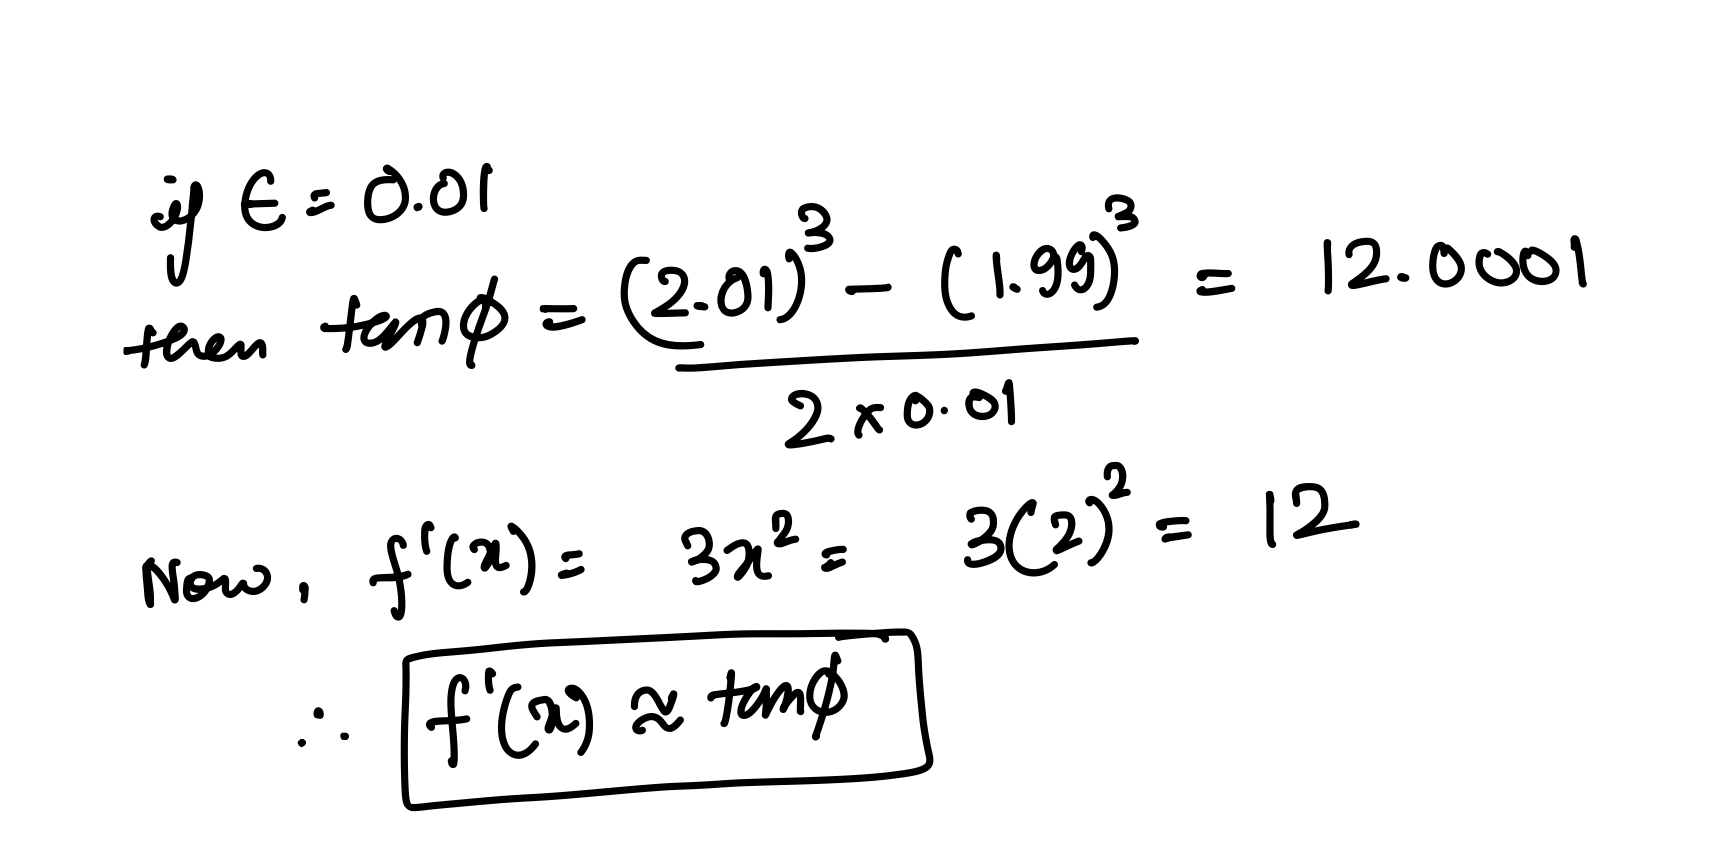

The value of $\tan$ becomes:
- $\tan = \frac{2.01^3 - 1.99^3}{2 \times 0.01} = \frac{8.120601 - 7.880599}{0.02} = 12.0001$

The derivative of $f(x)$ is:
- $f'(x) = 3x^2 = 3(2)^2 = 12$

Hence we can see $\frac{f(x+\epsilon) - f(x-\epsilon)}{2\epsilon} \approx f'(x)$.

**Note:** This is known as **Gradient Checking**.

Let's confirm the numbers in code.

### Checking the Formula with Numbers

Plugging the formula above into code: the approximation and the exact derivative ($3x^2=12$) should come out nearly identical.

In [ ]:
# The worked example from above: f(x) = x^3 at x = 2 with epsilon = 0.01
f = lambda x: x ** 3
x, eps = 2.0, 0.01

approx = (f(x + eps) - f(x - eps)) / (2 * eps)
exact = 3 * x ** 2

print("approximate derivative:", approx)     # about 12.0001
print("exact derivative      :", exact)      # 12.0

approximate derivative: 12.000099999999847
exact derivative      : 12.0


### How to Do Gradient Approximation in a Neural Network?

For backpropagation, every layer of the neural network has:
- Weights and biases $[W^1, b^1], [W^2, b^2], [W^3, b^3], \dots, [W^L, b^L]$
- Derivatives $[\Delta W^1, \Delta b^1], [\Delta W^2, \Delta b^2], \dots, [\Delta W^L, \Delta b^L]$
- The loss is a function of all of them: $Loss(W^1, b^1, W^2, b^2, \dots, W^L, b^L)$

**Note:** The weights and derivatives are 2-dimensional matrices.

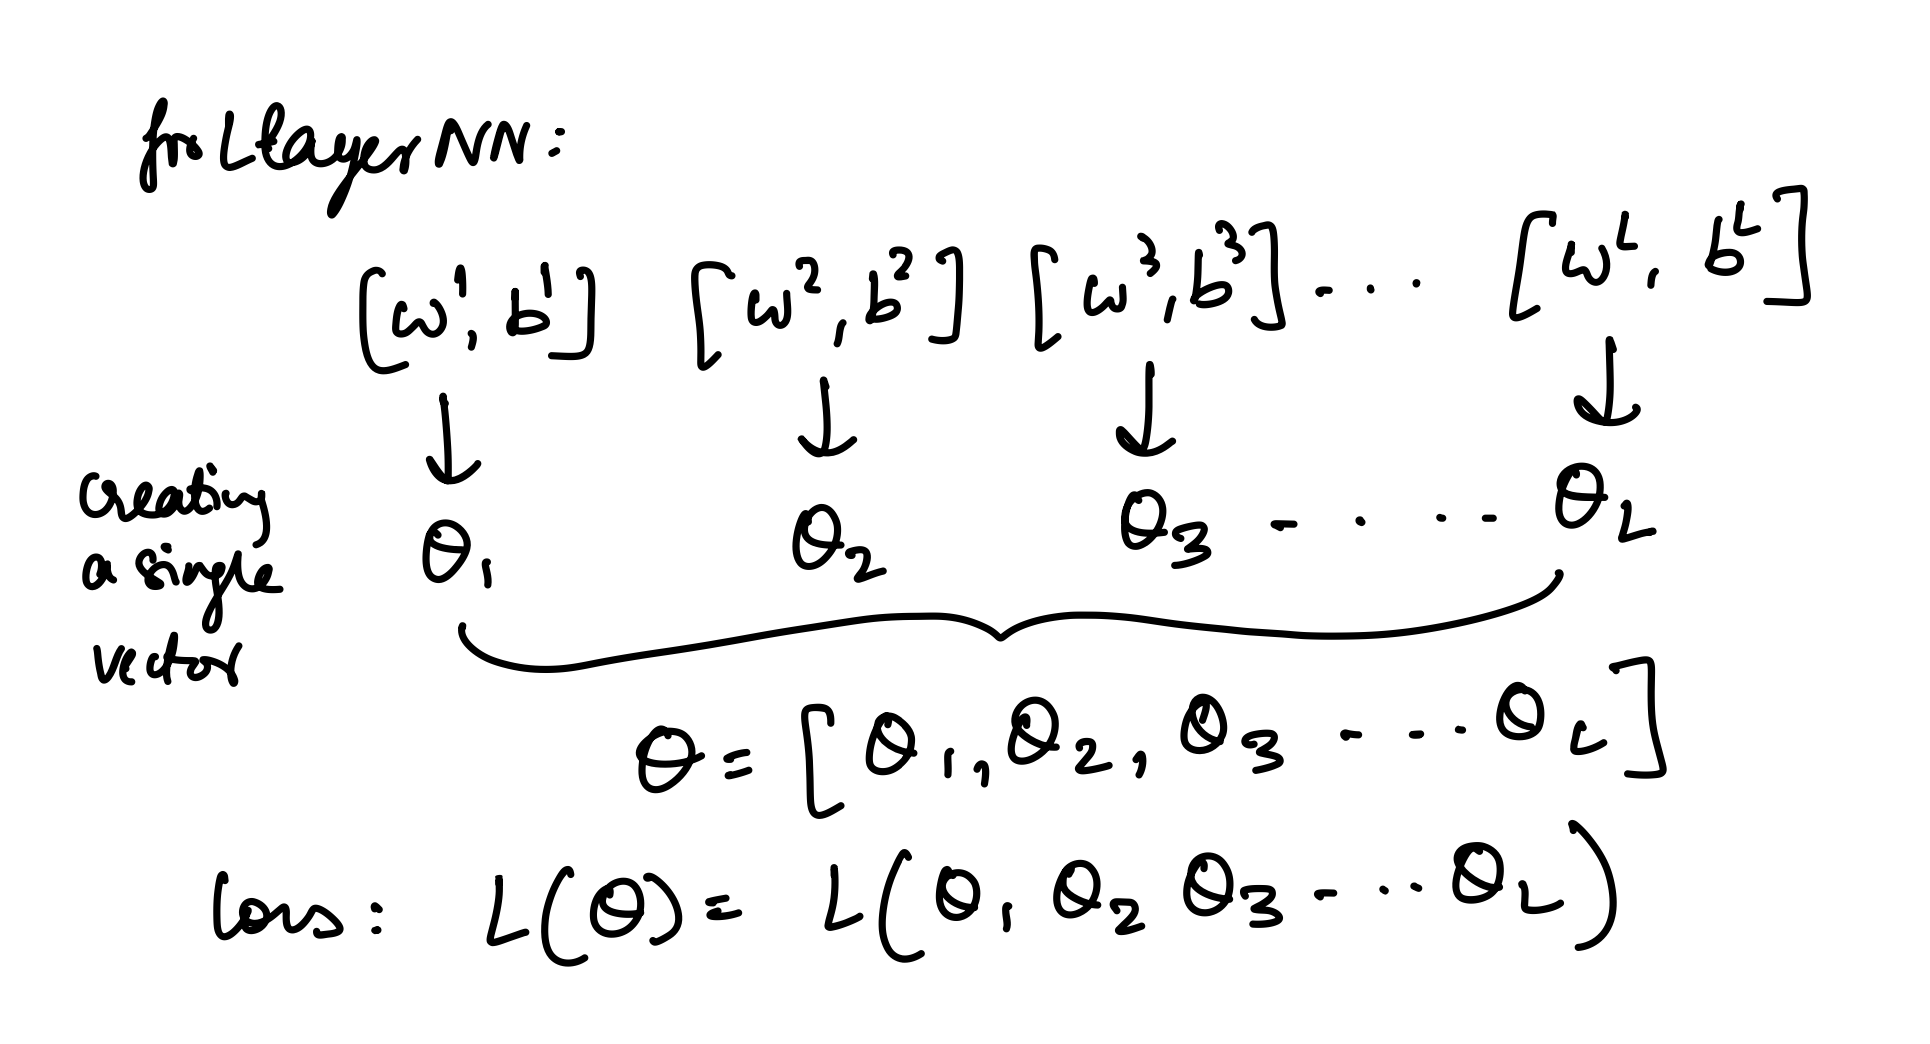

Let's create a single one-dimensional vector $\theta$ for every layer, by unrolling the weight and bias matrices and concatenating them:
- $\theta_1 = [W^1, b^1], \theta_2 = [W^2, b^2], \theta_3 = [W^3, b^3], \dots, \theta_L = [W^L, b^L]$

Similarly, the derivatives become:
- $\Delta\theta_1 = [\Delta W^1, \Delta b^1], \Delta\theta_2 = [\Delta W^2, \Delta b^2], \dots, \Delta\theta_L = [\Delta W^L, \Delta b^L]$

Now we concatenate all of $\theta_1, \theta_2, \dots, \theta_L$ into a single vector $\theta = [\theta_1, \theta_2, \dots, \theta_L]$, and the loss becomes:
- $Loss(\theta) = Loss(\theta_1, \theta_2, \dots, \theta_L)$

### How to Implement Gradient Checking?

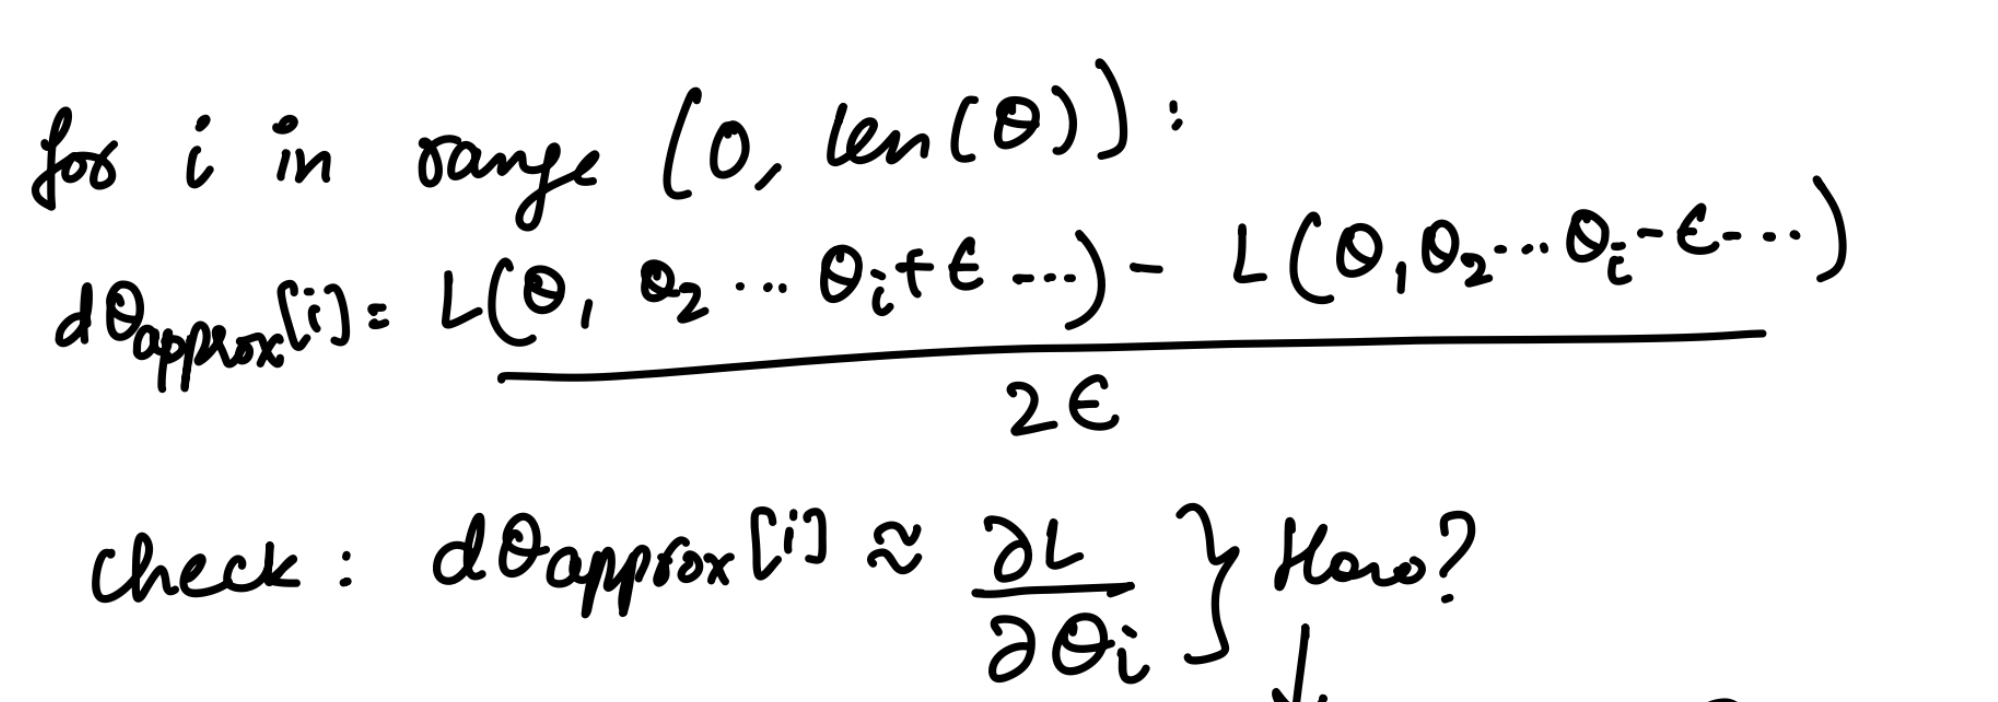

Gradient checking is implemented as:

for i in range(0, len($\theta$)):
- $d\theta_{approx}[i] = \frac{L(\theta_1, \theta_2, \dots, [\theta_i + \epsilon], \dots, \theta_L) - L(\theta_1, \theta_2, \dots, [\theta_i - \epsilon], \dots, \theta_L)}{2\epsilon}$

and then we check how close $d\theta_{approx}[i] \approx \frac{\partial L}{\partial \theta_i}$ is.

**Note:** The value of $\epsilon = 10^{-7}$.

### How to Evaluate if the Difference between the Approximation and the Actual Gradient Is Acceptable?

We compute the relative difference between the two gradient vectors:

$$\frac{\lVert d\theta_{approx} - \Delta\theta \rVert_2}{\lVert d\theta_{approx} \rVert_2 + \lVert \Delta\theta \rVert_2}$$

- If the value is $\leq 10^{-5}$, there is no issue.
- If the value is $> 10^{-5}$, there is a problem in backpropagation. A value around $10^{-3}$ or more is almost certainly a bug.

**Important:** Run gradient checking in 64-bit floats (`float64`). In 32-bit floats, the rounding error is larger than the effect of the tiny step $\epsilon = 10^{-7}$, and the check becomes meaningless.

Let's implement it on a tiny network, using exactly these steps: unroll $\theta$, loop over every value, and compare the two gradient vectors.

### Step 1 — A Tiny Network and Its Backprop Gradient

Gradient checking is slow (as the Doubt above explains), so we only ever run it on a tiny network: 2 linear layers with a `Tanh` in between, and a single small batch of 8 examples. Everything is cast to `.double()` (64-bit floats) — exactly the precision requirement from the Important note above. `tiny.zero_grad()` clears any old gradients, `.backward()` runs ordinary backpropagation, and `torch.cat([p.grad.reshape(-1) for p in tiny.parameters()])` is the “unroll every layer's gradients into one vector $\Delta\theta$” step described above — this is the gradient we're trying to verify.

In [ ]:
import torch.nn as nn

torch.manual_seed(0)
tiny = nn.Sequential(nn.Linear(5, 4), nn.Tanh(), nn.Linear(4, 3)).double()      # float64
xb = torch.randn(8, 5, dtype=torch.float64)
yb = torch.randint(0, 3, (8,))
check_loss = nn.CrossEntropyLoss()

# Gradients from backpropagation (autograd), unrolled into one vector: this is the "actual" Δθ
tiny.zero_grad()
check_loss(tiny(xb), yb).backward()
grad_backprop = torch.cat([p.grad.reshape(-1) for p in tiny.parameters()])

### Step 2 — The Numerical Approximation, $d\theta_{approx}$

This is the `for i in range(0, len(θ))` loop from the formula above, written out: for every single value in every parameter, nudge it up by $\epsilon$ and down by $\epsilon$, re-run the forward pass both times, and use the two losses to estimate that one value's gradient — exactly $\frac{L(\theta_i+\epsilon) - L(\theta_i-\epsilon)}{2\epsilon}$. Note the `torch.no_grad()`: we're only perturbing weights and reading off the loss, not tracking gradients through this process.

In [ ]:
# Numerical approximation of every value in θ: this is dθ_approx
def numerical_gradient(model, loss_fn, xb, yb, eps=1e-7):
    approx = []
    with torch.no_grad():
        for p in model.parameters():
            flat = p.view(-1)                                  # a view into the parameter's memory
            for i in range(flat.numel()):
                old = flat[i].item()
                flat[i] = old + eps
                loss_plus = loss_fn(model(xb), yb).item()
                flat[i] = old - eps
                loss_minus = loss_fn(model(xb), yb).item()
                flat[i] = old                                  # restore the weight
                approx.append((loss_plus - loss_minus) / (2 * eps))
    return torch.tensor(approx, dtype=torch.float64)

grad_numeric = numerical_gradient(tiny, check_loss, xb, yb)

### Step 3 — Comparing the Two Gradient Vectors

`relative_difference` is a direct implementation of the formula above. `report()` prints that relative difference for the whole network at once, and then **layer by layer** (`model.named_parameters()` gives each weight/bias matrix by name) — which is exactly what lets gradient checking tell you not just *that* something is wrong, but *where*, as the section below will show.

In [ ]:
def relative_difference(a, b):
    return (torch.norm(a - b) / (torch.norm(a) + torch.norm(b))).item()

def report(grad_numeric, grad_analytic, model):
    print(f"{'whole network':<14}{relative_difference(grad_numeric, grad_analytic):.2e}")
    start = 0 # layer number
    for name, p in model.named_parameters():
        end = start + p.numel()
        print(f"{name:<14}{relative_difference(grad_numeric[start:end], grad_analytic[start:end]):.2e}")
        start = end

### Step 4 — Run the Check

If backpropagation is implemented correctly, every number below should be far smaller than $10^{-5}$.

In [ ]:
report(grad_numeric, grad_backprop, tiny)

whole network 4.80e-09
0.weight      5.91e-09
0.bias        4.70e-09
2.weight      9.53e-09
2.bias        1.37e-09


Every value is far below $10^{-5}$, so backpropagation is correct for this network.

### Failure: What if the Backward Code Has a Bug?

Imagine we had written the backward pass by hand and forgot the gradient of the bias in the last layer. We simulate that bug by setting those gradients to zero.

**Ask Learners:** Will the whole-network difference be small or large? Will every layer be affected? Type your guess in the chat.

In [ ]:
grad_buggy = grad_backprop.clone()
grad_buggy[-3:] = 0.0                    # the last 3 values of θ are the bias of the last layer, the gradient we "forgot"

report(grad_numeric, grad_buggy, tiny)

whole network 3.92e-01
0.weight      5.91e-09
0.bias        4.70e-09
2.weight      9.53e-09
2.bias        1.00e+00


### What to Do if the Difference Is Really High?

The check does more than say that something is wrong: it says where. Only the last bias shows a large difference, so we look at the weight and bias matrices where the difference is high ($W^k$, $b^k$, where $k$ is the $k$-th layer) and then at each value in them to find the bug.

**Doubt by Learner:** Should gradient checking be done during training?

No. It needs two forward passes for every single value in $\theta$, so it is very slow. It is used for debugging only, on a small network and a small batch.

**Doubt by Learner:** Does gradient checking work with dropout?

No. Dropout drops different neurons in every iteration, so the loss changes randomly between the two forward passes and the numerical gradient is meaningless. Switch dropout off while checking.

### Let AI Plant a Bug and Let the Check Find It

**Step 1:** Ask an AI assistant: "Here is my gradient checking code (paste it). Suggest three subtle bugs that could appear in a hand-written backward pass of a linear layer, and show how to simulate each one on a gradient vector."

**Step 2:** Pick one suggestion and apply it to a copy of `grad_backprop`, the same way we set the last three values to zero.

**Step 3:** Run `report(grad_numeric, your_buggy_gradient, tiny)`. Does the report point to the layer where you planted the bug?

**Note for Instructor:**
- AI role: plays the bug author and proposes realistic bugs.
- Learner role: applies the bug and acts as the debugger, using only the report.
- Learning objective: practise localizing a gradient bug from the layer-wise relative difference.
- Guardrail: the learner does not trust what the AI says a bug will do. The gradient check is the judge, and any disagreement with the AI's prediction is worth discussing.

### Quiz: Interpreting a Gradient Check

**Question:** A gradient check on a network with custom layers gives a relative difference of $10^{-9}$ for every layer except one, whose weight gradient shows 0.8. What should you do next?

- A. Lower the learning rate and continue training
- B. Increase epsilon until the difference becomes smaller
- C. Collect more training samples and check again
- D. Inspect the backward code of that layer's weights

**Note for Instructor:** Run this as a chat poll. Correct option: D.

A relative difference of $10^{-9}$ means backpropagation matches the numerical gradient in every other layer. The large value 0.8 shows that the analytic gradient of this layer's weights is wrong, so the bug is in its backward code. The learning rate, the amount of data and the size of epsilon do not change whether the analytic gradient is correct.

### Interview Checkpoint: Debugging a Model Whose Loss Does Not Decrease

**Ask Learners:** An interviewer says: "My network's training loss is not going down. Walk me through how you would debug it." Type the first three steps you would take.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: go from the cheapest check to the most expensive one. Check the data and labels, check the loss and the output layer (for example softmax before `nn.CrossEntropyLoss`), try to overfit one small batch, then look at the learning rate, and use gradient checking for custom layers.
- Common weak answer: "Add more layers or train for more epochs."
- Strong answer: a clear order of checks, including overfitting a single batch as a sanity test (if the model cannot memorize 32 samples, something is broken), and gradient checking only where custom backward code exists.

# Single Evaluation Metric

Backpropagation is verified and we know which knobs to turn. Now a different question: after every experiment, how do we decide that the new model is actually better? In our baseline we tracked two metrics, precision and recall, and they do not always agree.

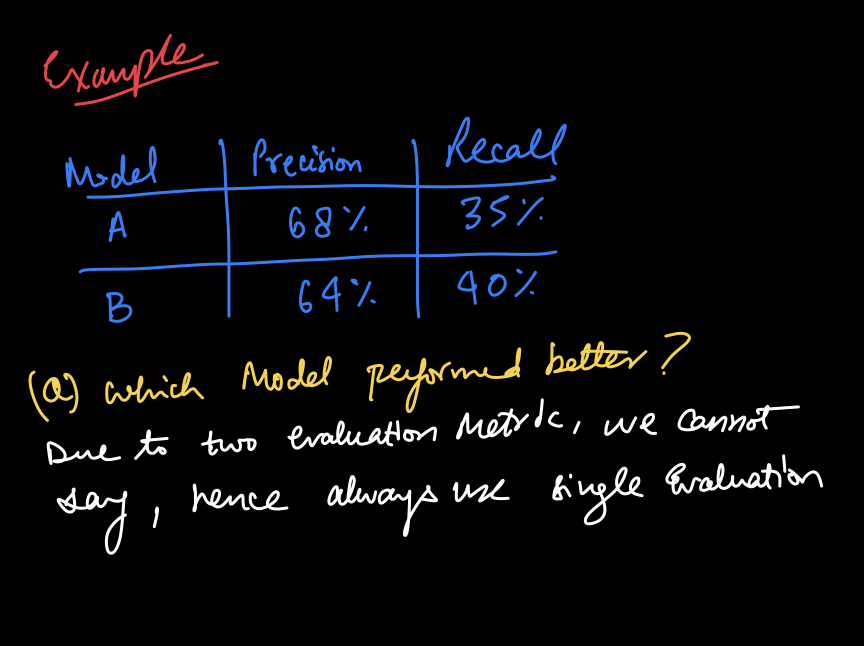

Suppose Model A has Precision = 68% and Recall = 35%, and Model B has Precision = 64% and Recall = 40%.

**Ask Learners:** Which model performed better, A or B? Vote A or B in the chat.

We cannot say. Model A is better on precision and Model B is better on recall. With two numbers, every comparison turns into an argument, and every experiment slows down. That is why we use a **single evaluation metric**.

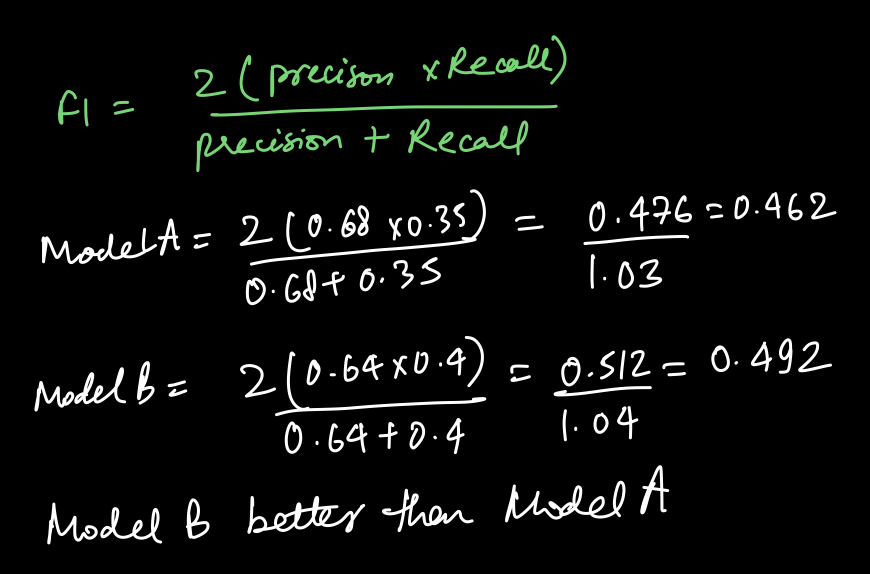

### How About the F1 Score? Will That Help?

Yes. The F1 score combines precision and recall into one number:

$F1Score = \frac{2 \times Precision \times Recall}{Precision + Recall}$

Therefore:
- F1 for Model A: $\frac{2 \times 0.68 \times 0.35}{0.68 + 0.35} = \frac{0.476}{1.03} = 0.462$
- F1 for Model B: $\frac{2 \times 0.64 \times 0.40}{0.64 + 0.40} = \frac{0.512}{1.04} = 0.492$

Combining precision and recall into the F1 score shows that Model B performs better than Model A, even though Model A has the higher precision.

**Note:** It is always good practice to use a single evaluation metric, or to combine metrics into one.

**Ask Learners:** Model X has Precision = 0.95 and Recall = 0.30. Model Y has Precision = 0.60 and Recall = 0.55. Which model has the better simple average of precision and recall, and which has the better F1? Type X or Y for each.

The simple average favors X (0.625 against 0.575). The F1 favors Y: F1 for X is $\frac{2 \times 0.95 \times 0.30}{0.95 + 0.30} = 0.456$, and F1 for Y is $\frac{2 \times 0.60 \times 0.55}{0.60 + 0.55} = 0.574$. F1 is the harmonic mean, so it is pulled down by the smaller of the two numbers. It punishes a model that is excellent at one thing and poor at the other.

### What if We Cannot Combine the Metrics Together?

Let's take an example. Suppose we have three models (A, B, C) such that:

| Model | F1Score | Running Time |
| :-- | :--| :--|
|A| 80% | 100ms |
|B| 92% | 180ms |
|C| 95% | 250ms |

We want a model that has the maximum F1 score and the minimum running time. We cannot combine F1 score and running time into a single number in a sensible way.

Now what if we select the model that has the maximum F1 score, **such that** the running time is $\leq$ a threshold ($\tau = 200$ ms)?

**Ask Learners:** Which model do we select now? And which one if the threshold were 300 ms? Type both answers in the chat.

With a threshold of 200 ms, the best model is Model B, because Model C is too slow. With a threshold of 300 ms, it is Model C. The threshold comes from the business, not from the data: for example, a fraud check must finish before the payment screen times out.

### Imagine We Have N Metrics That Cannot Be Combined. What to Do?

Pick one metric on which we want the model to be as good as possible, and put conditions on the remaining $N-1$ metrics.

**Note:** The metric on which the model maximizes itself is called the **Optimizing metric**. The metrics on which conditions are applied are called **Satisficing metrics**.

In practice, the satisficing metrics are usually engineering limits such as latency, model size or memory, and the optimizing metric is the quality metric such as F1.

### Implementing the F1 Score

Now that we understand the importance of a single evaluation metric, let's look at the F1 score of our baseline model. Our training function already computed it after every epoch, using scikit-learn. In larger projects, the `torchmetrics` library gives the same metrics as GPU-friendly modules.

**Note:** There are different ways to average the F1 score over classes:
- The **micro-averaged** F1 score pools the per-sample classifications of all classes and then calculates one overall F1 score.
- The **macro-averaged** F1 score calculates the F1 score of every class and takes a simple average over the classes.

Our training function used the macro average.

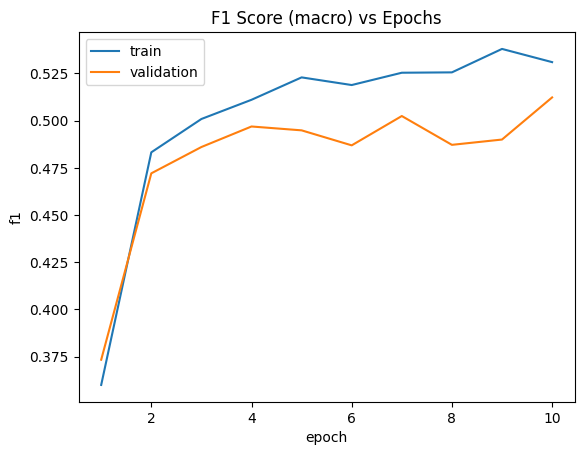

In [ ]:
plot_history(history, "f1", "F1 Score (macro) vs Epochs")

Just by using the F1 score, we understand the performance of the model much more clearly.

### A Surprise about Micro-Averaged F1

**Ask Learners:** A teammate says: "For our four-class problem, the micro-averaged F1 will give exactly the same number as plain accuracy." Do you agree? Vote with an emoji: 👍 same number, 👎 different number.

### Check Your Prediction

`predict()` is the same helper from earlier — note it needs no retraining, we're just scoring the model we already have. The five metrics below let you check your prediction above.

In [ ]:
from sklearn.metrics import accuracy_score

_, val_pred = predict(model, X_val_t)
val_pred = val_pred.numpy()

print("accuracy        :", round(accuracy_score(y_val, val_pred), 4))
print("micro precision :", round(precision_score(y_val, val_pred, average="micro"), 4))
print("micro recall    :", round(recall_score(y_val, val_pred, average="micro"), 4))
print("micro F1        :", round(f1_score(y_val, val_pred, average="micro"), 4))
print("macro F1        :", round(f1_score(y_val, val_pred, average="macro"), 4))

accuracy        : 0.5306
micro precision : 0.5306
micro recall    : 0.5306
micro F1        : 0.5306
macro F1        : 0.5123


The first four numbers are identical. Only the macro F1 is different.

**Why does this happen?** In a single-label problem, every wrong prediction is counted twice: once as a false positive for the class that was predicted, and once as a false negative for the class that was true. So the total number of false positives equals the total number of false negatives, and both equal the number of mistakes. When everything is pooled, micro precision, micro recall, micro F1 and accuracy all reduce to the same fraction: the correct predictions divided by all predictions.

So micro-averaged F1 gives no extra information beyond accuracy for this kind of problem. The averaging that can show something different is the macro average, which treats every class equally. Let's see when that matters.

### A Synthetic Worst Case

To see when macro F1 and accuracy disagree, consider a model that always predicts the majority class on a 95/5 imbalanced two-class problem (completely synthetic, not our customer data) — accuracy looks great, but does it deserve to?

In [ ]:
# 95% of the samples belong to class 0, and the model always predicts class 0
y_true = np.array([0] * 95 + [1] * 5)
y_pred = np.zeros(100, dtype=int)

print("accuracy :", accuracy_score(y_true, y_pred))
print("micro F1 :", round(f1_score(y_true, y_pred, average="micro"), 3))
print("macro F1 :", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 3))

accuracy : 0.95
micro F1 : 0.95
macro F1 : 0.487


Accuracy and micro F1 report 0.95 for a model that never finds a single sample of class 1. The macro F1 is 0.487, because the F1 of class 1 is 0 and every class carries the same weight.

**Note for Instructor:** This surprise corrects a common belief that micro-averaged F1 is somehow smarter than accuracy. Give learners a moment to react in the chat before moving on.

### Quiz: Choosing the Right Average

**Question:** A single-label classifier with four classes always predicts the majority class, which covers 90% of the data. Which metric exposes this problem?

- A. Micro-averaged F1 score
- B. Macro-averaged F1 score
- C. Micro-averaged recall
- D. Overall accuracy

**Note for Instructor:** Run this as a chat poll. Correct option: B.

For single-label multi-class data, micro-averaged precision, recall and F1 are all equal to accuracy, so each of them would report 90% and hide the problem. Macro-averaging computes the F1 of each class first and then takes the plain average. The three classes that are never predicted get an F1 of 0, so the macro F1 falls far below 90%.

### Interview Checkpoint: Is 95% Accuracy Good Enough to Ship?

**Ask Learners:** An interviewer says: "Our fraud model has 95% accuracy. Can we ship it?" Type what you would ask or check first.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: accuracy depends on the class balance. Compare it with the majority-class baseline, look at precision and recall of the fraud class (or macro F1), and check the satisficing constraints such as latency.
- Common weak answer: "Yes, 95% is very high."
- Strong answer: asks what share of transactions is fraud, compares against always predicting "not fraud", reports precision and recall on the fraud class, and connects the metric to business cost (a missed fraud versus a blocked genuine customer).

### Evaluating the Model on the Test Data

With this, let's check the performance of the model on the test data.

### Compute It

Same `predict()` + macro F1 pattern, now on the held-out test set, compared side by side with the validation score.

In [ ]:
_, test_pred = predict(model, X_test_t)
test_pred = test_pred.numpy()

print("Test macro F1      :", round(f1_score(y_test, test_pred, average="macro"), 4))
print("Validation macro F1:", round(f1_score(y_val, val_pred, average="macro"), 4))

Test macro F1      : 0.5053
Validation macro F1: 0.5123


The model has similar results on the validation and test datasets. This is because the validation and test data come from the same distribution.

Imagine if the validation data had Indian customers' information while the test data had UK customers' information.

**Ask Learners:** Can we still rely on the results of the validation and test sets? Answer yes or no in the chat.

No. The people in India and the UK live in completely different scenarios, so the distributions of the validation and test sets would be entirely different. A model tuned on one would be judged on the other, and the validation score would tell us nothing about the test score.

### How to Make the Distribution the Same in the Validation and Test Sets?

Pool all the data, shuffle it, and then split it, so that both the validation set and the test set contain customers from India and from the UK. The two sets then describe the same population.

In industry, the more common version of this problem is **distribution shift**: the data the model sees in production slowly stops looking like the data it was validated on. Keeping the validation and test sets close to the real production data is what keeps our metric honest.

# Human-level Performance

Our model scores roughly 0.5 F1 on the test set. Is that good or bad? A number on its own means nothing. It needs something to be compared with.

A first comparison is a trivial model. Let's see how well one that does no learning would perform.

**Note for Instructor:** If the test F1 printed in the previous section is not close to 0.5 on your run, quote the printed value instead.

### The Code

`y_train.mode()` finds the most frequent class (the “always guess this” baseline), and we compare always guessing it against the validation labels.

In [ ]:
print(y_train.value_counts(normalize=True).sort_index().round(3))

majority_class = y_train.mode()[0]
print("\nAlways predicting the majority class -> validation accuracy:", round((y_val == majority_class).mean(), 3))
print("Random guessing among 4 classes      -> about", 1 / 4)

Segmentation
0    0.242
1    0.237
2    0.256
3    0.264
Name: proportion, dtype: float64

Always predicting the majority class -> validation accuracy: 0.256
Random guessing among 4 classes      -> about 0.25


If we consider a trivial model that guesses at random among 4 classes, its score is about $\frac{1}{4} \times 100 = 25$%. Always predicting the most frequent class does only slightly better. Our model, at roughly 50%, is clearly better than both, so it has learned something.

But what if a human tries to classify the same customers and gets an F1 score of 60%? Is the model good then?

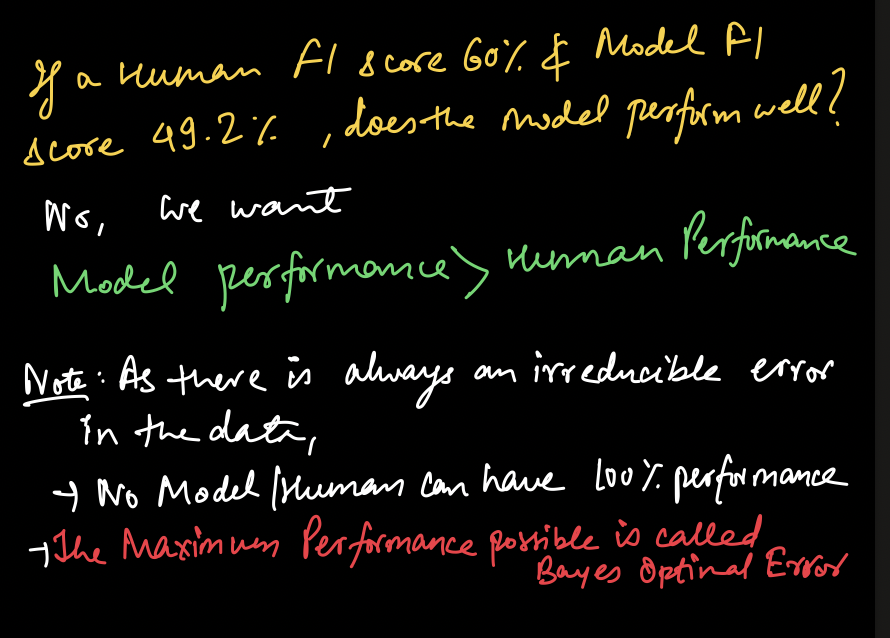

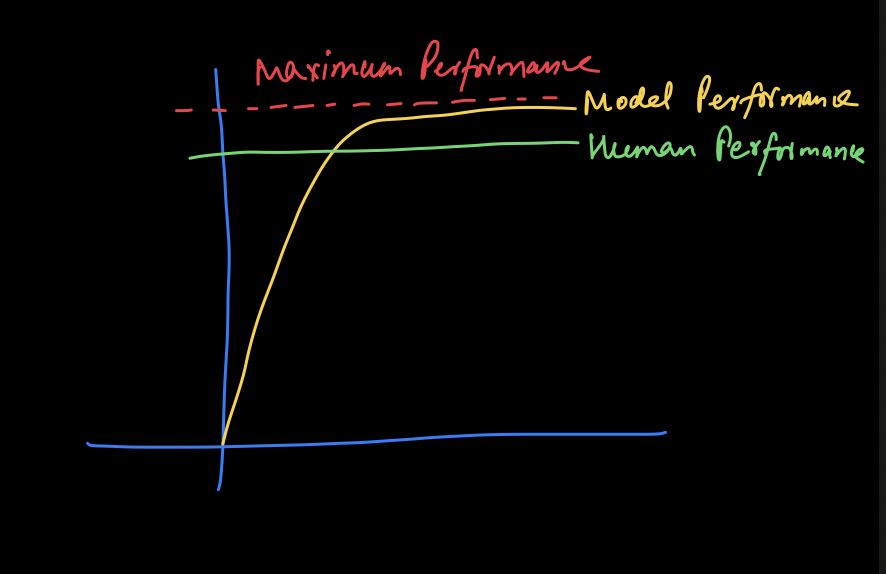

No. In most business problems, we want the model's performance to be better than, or at least close to, human performance. Even though the model is better than a trivial model, it is good practice to compare it with human performance.

**Note:** There is always some irreducible error in the data. No model and no human can reach 100% performance. The maximum performance that is possible, or the least error that can be attained for a problem, is called the **Bayes Optimal Error**.

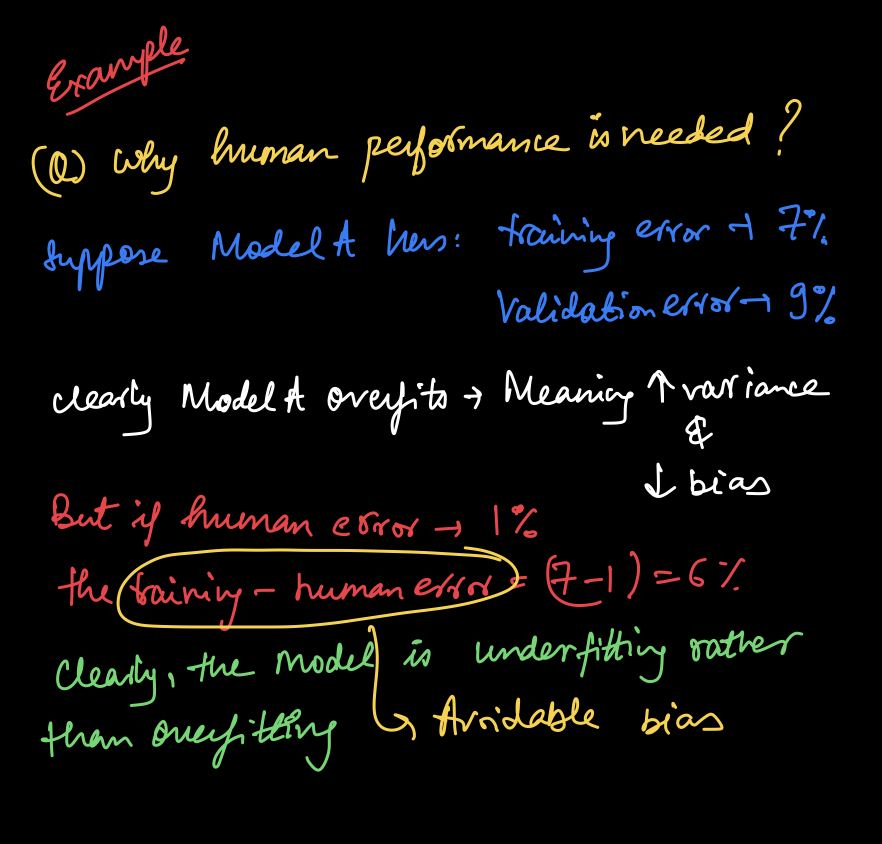

### Why Compare to Human-Level Performance?

Humans do many tasks efficiently and with high accuracy, for example classifying different brands of cars or recognizing speech. Human-level performance is also a very useful reference for deciding between **bias** and **variance**.

**Ask Learners:** Suppose we classify Maruti cars versus Honda cars. Human error is 1%. The model's training error is 7% and its validation error is 9%. Which problem should we work on first: 📉 bias or 📈 variance? Vote with an emoji.

Without a human reference, the gap between training and validation error (2%) would push us toward variance. But the gap between human error and training error is $7\% - 1\% = 6\%$. This shows that the model is not fitting the training data well. It has high bias, so bias is the problem to focus on.

**Note:** The gap between human error and training error is called the **Avoidable Bias**. Here, human-level error is used as a proxy for the Bayes optimal error.

What if the images are blurry, so that human error rises to 6.5% while the model's errors stay the same? Now the avoidable bias is only $7\% - 6.5\% = 0.5\%$, while the variance (the gap between validation and training error) is $9\% - 7\% = 2\%$. The training error is close to human level, so the model fits the training data well. The validation error is higher than the training error, so the model has high variance, and variance is the problem to focus on.

The same model, the same errors, and two different next steps. The human-level reference is what tells us which one.

### Quiz: Bias or Variance?

**Question:** For a task, the best human expert team makes 2% error. A model has 3% training error and 8% validation error. What should you work on first?

- A. Reducing bias by training a much bigger network
- B. Collecting more expert labels to lower human error
- C. Training longer until the training error reaches 0%
- D. Reducing variance with regularization or more data

**Note for Instructor:** Run this as a chat poll. Correct option: D.

Avoidable bias is the training error minus the human-level error: 3% − 2% = 1%. Variance is the gap between validation and training error: 8% − 3% = 5%. The variance gap is five times larger, so the model fits the training data close to human level but does not generalize. Regularization or more diverse data attacks that gap, while a bigger network or longer training would mainly reduce the small bias term.

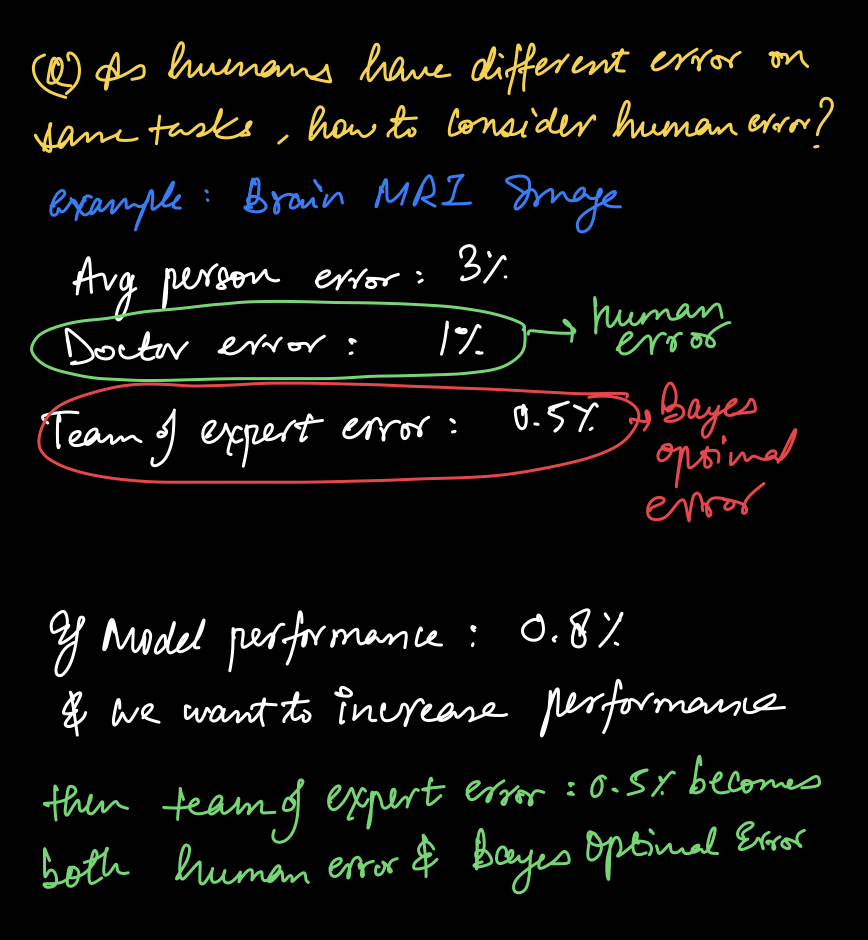

### As Humans Have Different Errors on the Same Task, Which Human Error Should Be Considered?

Let's take an example. We have a brain MRI image and we check whether the patient has a tumor or not. Suppose:
- An average person's error is 3%
- A doctor's error is 1%
- A team of expert doctors has an error of 0.5%

**Ask Learners:** Which one should we consider as the human error, and which one as the Bayes optimal error? Type your answer in the chat.

Since a doctor is in the field of study, we consider 1% as the human error. The Bayes optimal error is the best that can be achieved, so we use the 0.5% error of the team of expert doctors.

### Can the Bayes Optimal Error Also Be Used as the Human Error?

Yes, it can be. Suppose the human error taken is 1%, the Bayes optimal error is 0.5%, and the model has a training error of 0.7% and a validation error of 0.8%. The model is already performing quite well on this dataset.

If we want to increase the performance further, we make the Bayes optimal error equal to the human error, which is 0.5%. The avoidable bias is then $0.7\% - 0.5\% = 0.2\%$, so the model has to do more bias reduction before variance reduction to perform much better.

**Ask Learners:** For a task, an employee makes 0.8% error, a senior makes 0.4% error and a manager makes 0.2% error. Which one is the best estimate of the Bayes optimal error? Type your answer in the chat.

The manager's error of 0.2%, because the Bayes optimal error is the lowest error that can be attained, and the best human is our closest estimate of it.

### Interview Checkpoint: Bayes Error

**Ask Learners:** An interviewer asks: "What is the Bayes error, and why can it be impossible to reach 0% error on a real problem?" Type a one-line answer in the chat.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: Bayes error is the lowest error any model can reach. It is above zero because of noise, ambiguity, overlapping classes and sometimes wrong labels in the data.
- Common weak answer: "It is the error of the best model that we have trained so far."
- Strong answer: defines it as an irreducible floor, uses human-level error as a proxy for it, and shows how the gap between training error and this proxy (the avoidable bias) decides whether to keep optimizing or to stop.

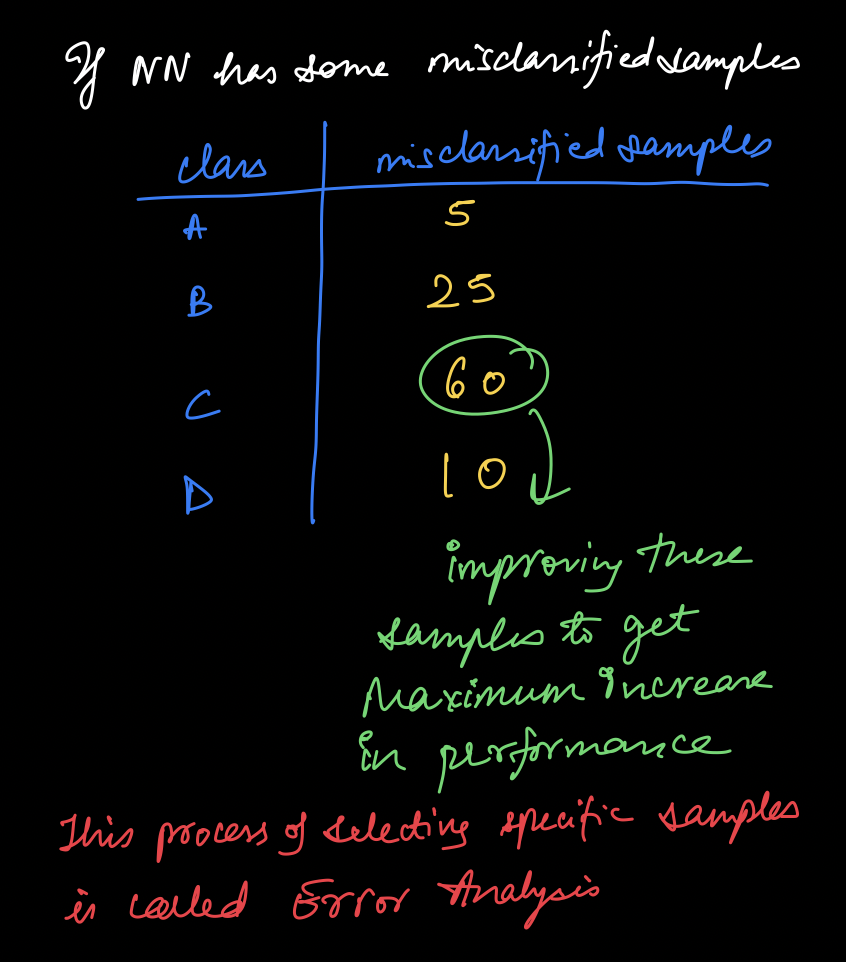

### What if the Model Barely Improves After Every Possible Hyperparameter Tuning?

Now imagine that after every possible hyperparameter tuning, the model performance improves only slightly.

**Ask Learners:** What should we do to make the model perform better when tuning no longer helps? Drop your idea in the chat.

We manually look for the cause of the errors and try to resolve it. This process of manual analysis is called **Error Analysis**.

### How to Perform Error Analysis?

- Take the misclassified samples of the validation set.
- Count the samples for each class.
- The count tells us what share of the errors comes from which class, so we can decide which class to fix to reduce the error the most.

Let's take an example. Suppose in our data, the misclassified samples are:
- 5 samples of class A
- 25 samples of class B
- 60 samples of class C
- 10 samples of class D

**Ask Learners:** Which class should we work on the most? Type A, B, C or D.

Class C. Of the 100 errors, 60 come from class C, so fixing them can remove at most 60% of the current errors. In the same way, we can work on the misclassified samples of class B in parallel, which reduces the error further.

Now let's do the same on our own model.

### Visualize Where the Model Gets Confused

`confusion_matrix` cross-tabulates true vs. predicted classes, and `ConfusionMatrixDisplay` draws it as a heatmap — the diagonal is every correct prediction, everything off the diagonal is a mistake.

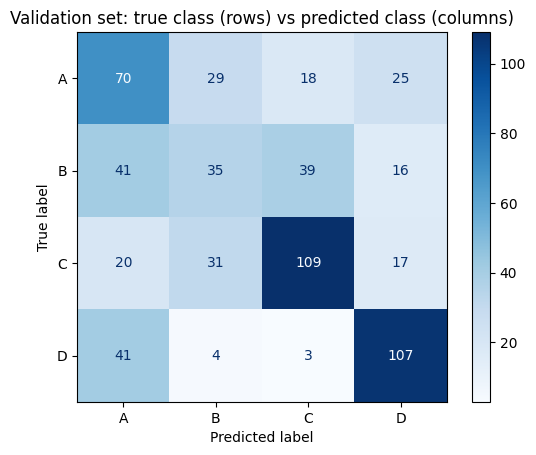

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, val_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues")
plt.title("Validation set: true class (rows) vs predicted class (columns)")
plt.show()

### Which Class Contributes the Most Errors?

`cm.sum(axis=1) - np.diag(cm)` takes each class's total row count (how many times it was the true label) and subtracts how many of those were correctly predicted (the diagonal), leaving each class's count of misclassified examples. Dividing by the total gives each class's *share* of all the mistakes — useful for deciding where to focus error analysis next.

In [ ]:
errors = pd.Series(cm.sum(axis=1) - np.diag(cm), index=classes, name="misclassified")
print(pd.DataFrame({"misclassified": errors, "share of all errors": (errors / errors.sum()).round(2)}))

   misclassified  share of all errors
A             72                 0.25
B             96                 0.34
C             68                 0.24
D             48                 0.17


### Error Analysis with an AI Assistant

The table above is a summary, and a summary is exactly the kind of thing an AI assistant can help us reason about. But we must not paste raw customer rows into an external AI tool. In a real company, customer data is private. We share only aggregated numbers.

**Step 1:** Copy the table of misclassified samples per class, and the confusion matrix, as text.

**Step 2:** Ask the AI assistant: "Here is the confusion matrix of my 4-class customer segmentation model. Which class should I investigate first? Give me three hypotheses for why the model confuses those classes."

**Step 3:** Choose one hypothesis and test it on the validation data. The code below shows how often the model is wrong for each spending score, as one example of a test.

**Step 4:** Post in the chat whether the data supports the hypothesis or not.

**Note for Instructor:**
- AI role: proposes hypotheses from aggregated numbers only.
- Learner role: selects one hypothesis and tests it on the data.
- Learning objective: treat error analysis as a hypothesis-and-test loop, and build the habit of not sharing private data with external tools.
- Guardrail: an AI hypothesis is not a finding. It becomes a finding only after the data confirms it, and the learner reports the number that confirms or rejects it.

### Rebuild an Unscaled, Readable Validation Table

`X_val` was overwritten by the scaler earlier, so to look at errors in terms of real, human-readable values we re-run the same split (same `random_state`, so it's identical) to recover `X_val_orig` before scaling, and attach the true/predicted class and whether each row was wrong.

In [ ]:
# Reconstruct X_val_df as a pandas DataFrame using the original unscaled X_val
import pandas as pd

# X_val was originally a DataFrame before being scaled, we can reconstruct it from the original split
_, X_val_orig, _, _ = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)
val_df = X_val_orig.copy()

val_df["true"] = [classes[i] for i in y_val.values]
val_df["pred"] = [classes[i] for i in val_pred]
val_df["wrong"] = val_df["true"] != val_df["pred"]

### Slice by a Feature and Look for a Pattern

The one-hot `Spending_Score_*` columns are collapsed back into a single readable column with `idxmax`, then we group by it and look at the error rate per group — a quick way to check whether the model is systematically worse for a particular kind of customer. Try swapping in a different column from `val_df` to look for other patterns.

In [ ]:
spend_cols = [c for c in val_df.columns if c.startswith("Spending_Score_")]
val_df["Spending_Score"] = val_df[spend_cols].idxmax(axis=1).str.replace("Spending_Score_", "")

val_df.groupby("Spending_Score")["wrong"].agg(["mean", "count"]).round(3)

,mean,count
Spending_Score,,
Average,0.435,154
High,0.552,87
Low,0.464,364


This is only one example of a test. Replace `Spending_Score` with another column, such as `Profession` or `Graduated`, or group by the true class, to test the hypothesis you chose.

# Multi-task Learning

So far, every customer had exactly one label: A, B, C or D. What if a single input can carry several labels at the same time?

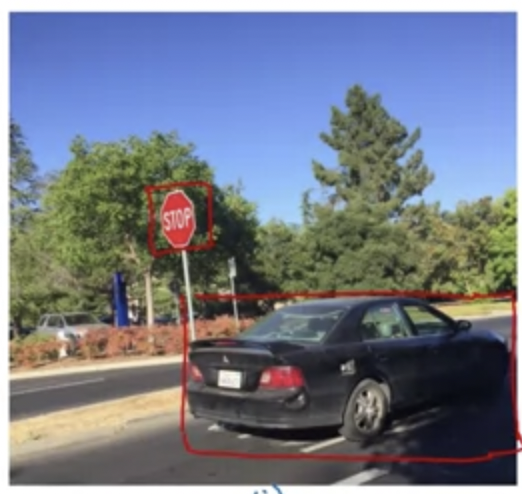

### Why Do Neural Networks Work for Complex Real-World Problems?

Suppose we are creating an autonomous vehicle, which in a particular frame checks whether the image contains any pedestrian, car, stop sign or traffic light. In the image above, there is a stop sign and a car at the same time.

### How Would Classical Machine Learning Do This Task?

By creating 4 different models, one that checks for pedestrians, one for cars, one for stop signs and one for traffic lights. Each model identifies one object on its own.

**Note:** With 4 separate models, no information is shared among them, and the system has to run 4 models for every frame, which costs 4 times the inference compute.

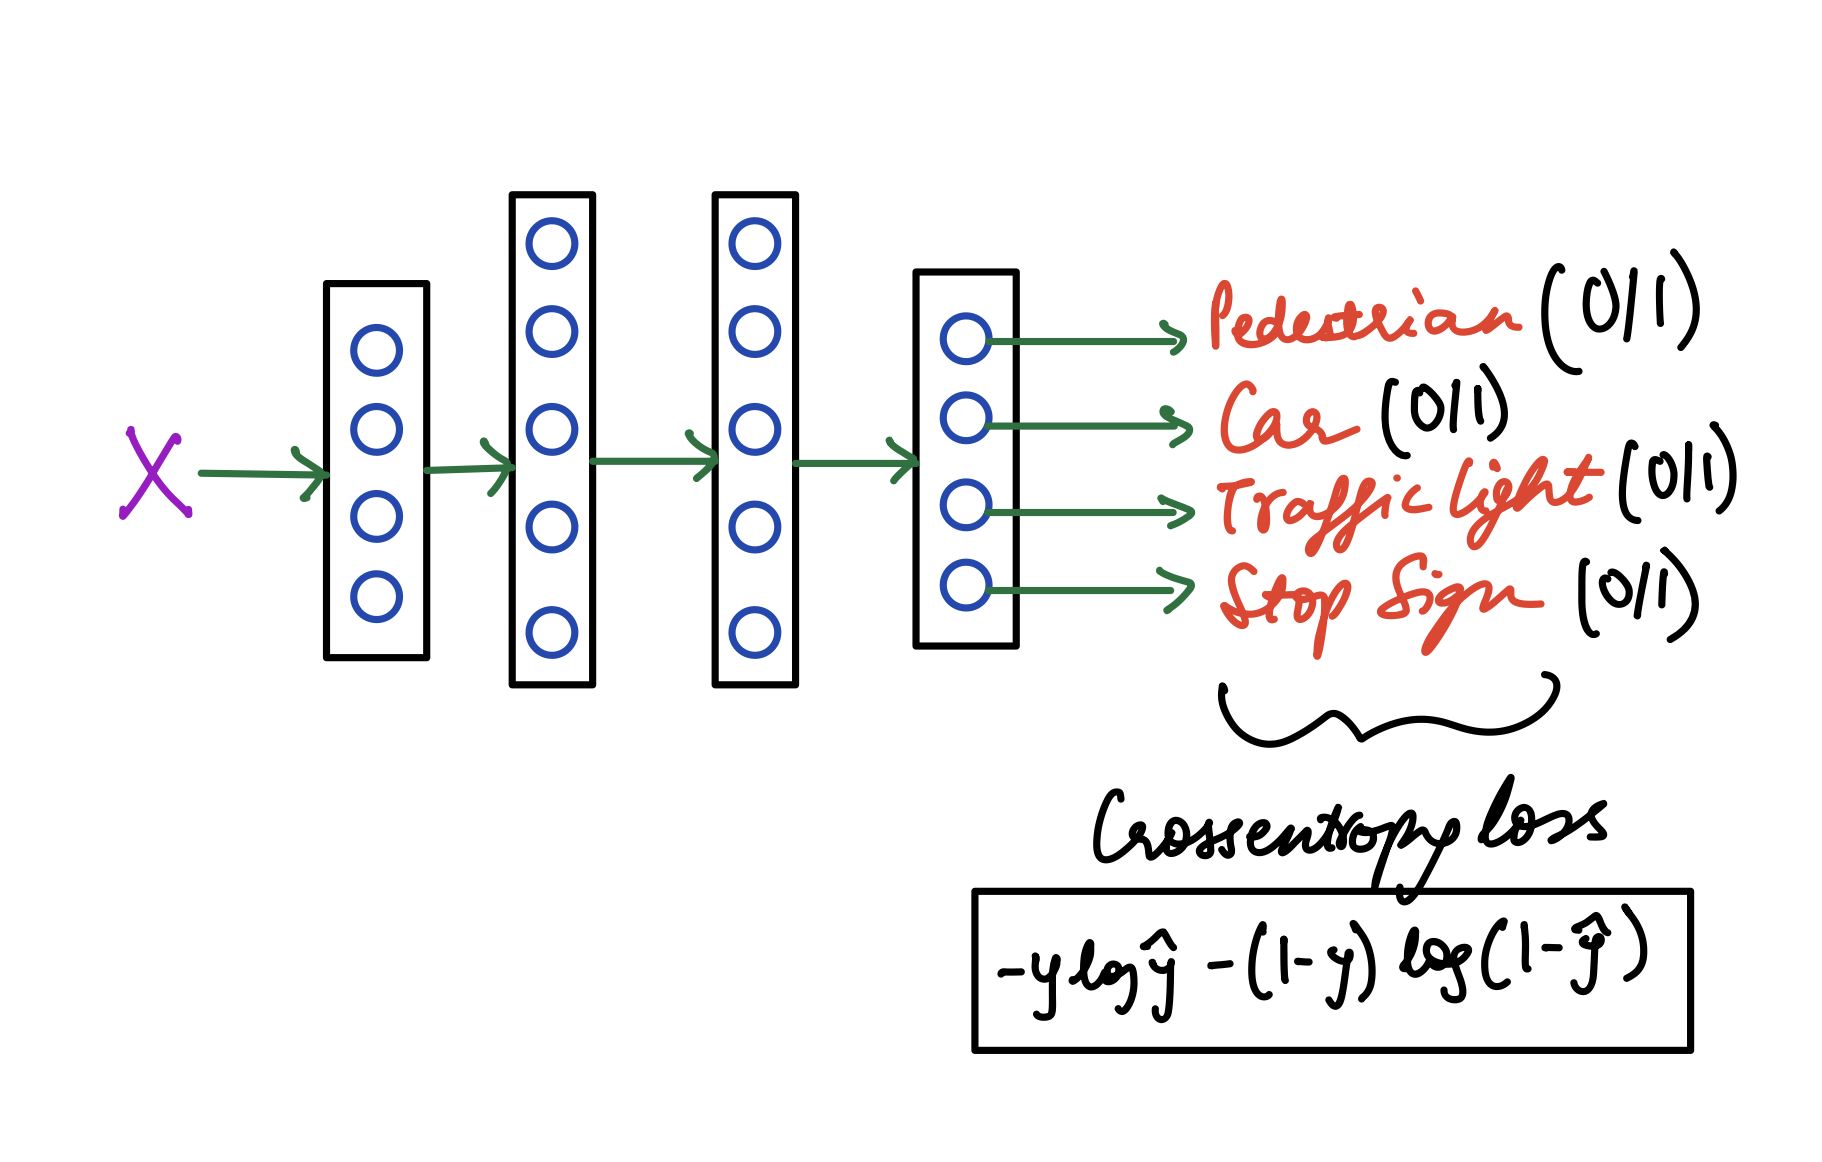

### How Does a Neural Network Check 4 Objects in a Single Image?

By creating an output layer with 4 neurons, where each neuron represents one object. A value of 1 means the object is present and 0 means the object is not present.

These neurons share the features learned by the previous hidden layers. Sharing features can make the model perform better, and one forward pass answers all four questions.

**Note:** This is known as **Multi-task Learning**.

### Why Is Softmax Not Used Here?

Softmax is useful when we need to pick one class over several classes. Here we want to identify some classes among several classes, because a frame can have a car and a stop sign at the same time. Hence **sigmoid** is used with the **binary cross-entropy** loss function. In PyTorch, that is `nn.Linear(hidden, 4)` followed by `nn.BCEWithLogitsLoss()`, with the targets given as a vector of 0s and 1s.

Let's see the difference on the same four scores.

### Compare the Two

`torch.softmax` forces every row to sum to 1 (the classes compete), while `torch.sigmoid` treats every logit independently as its own yes/no probability — which is what we need when more than one label can be true at once.

In [ ]:
logits = torch.tensor([[2.0, 1.5, -1.0, 3.0]])      # scores for: pedestrian, car, traffic light, stop sign

print("softmax:", torch.softmax(logits, dim=1).round(decimals=3))   # compete with each other, sum to 1
print("sigmoid:", torch.sigmoid(logits).round(decimals=3))          # independent yes/no probabilities

softmax: tensor([[0.2290, 0.1390, 0.0110, 0.6210]])
sigmoid: tensor([[0.8810, 0.8180, 0.2690, 0.9530]])


With softmax, the probabilities add up to 1, so the stop sign (0.62) pushes the car down to 0.14. With sigmoid, the car gets 0.82 and the stop sign gets 0.95 at the same time, which is what we want when both are in the frame.

### Quiz: Output Layer for Multiple Labels

**Question:** A single network must tag every photo with any combination of "beach", "dog" and "sunset". Several tags can be true in the same photo. Which output layer and loss fit this problem?

- A. Three independent sigmoid outputs trained with binary cross-entropy
- B. One softmax over the three tags trained with categorical cross-entropy
- C. Three ReLU outputs trained with mean squared error
- D. One sigmoid output trained with categorical cross-entropy

**Note for Instructor:** Run this as a chat poll. Correct option: A.

A photo can contain a beach, a dog and a sunset at the same time, so each tag is its own yes-or-no question. Sigmoid outputs treat every tag independently, and binary cross-entropy is the matching loss. Softmax forces the probabilities to sum to 1, which makes the tags compete as if only one of them could be present.

### Interview Checkpoint: Multi-task Learning

**Ask Learners:** An interviewer asks: "Why would you train one multi-task network instead of four separate binary models?" Type one advantage and one risk.

**Note for Instructor:** Reveal the model answer after a few responses.
- Expected reasoning: the tasks share hidden features, which can improve each task, and one forward pass serves all tasks, which lowers inference cost and latency. The risk is that tasks can interfere with each other when they need very different features, or when one loss dominates the others.
- Common weak answer: "It is simpler to write the code."
- Strong answer: names shared representation and lower inference cost as the advantages, names task interference and loss balancing as the risks, and says that this matters most when the compute budget or latency limit is tight.

# Recap

Let's follow the path we took today, because it is the same path to follow every time a model does not work.

- **Diagnose before changing anything.** Match the symptom to the knob: underfitting, overfitting, or a validation set that does not represent the data. Change one thing at a time.
- **Tune the settings that matter most.** The learning rate first, with random search on a sensible scale, and a finer search only in the promising region.
- **Verify the machinery.** Gradient checking catches bugs in custom backward code, and it tells us which layer to look at.
- **Measure with one honest metric.** Use one optimizing metric with satisficing constraints, and pick the average that does not hide a poor class. Keep the validation and test sets from the same distribution.
- **Judge against a reference.** Human-level performance, as a proxy for Bayes error, splits the problem into avoidable bias and variance.
- **Analyze the errors.** When tuning stops helping, count the mistakes per class and test hypotheses on the data, with AI as a source of hypotheses and not as a source of answers.
- **Handle several labels at once.** Use sigmoid outputs with binary cross-entropy for multi-task problems.

**Ask Learners:** At the start of the class, we asked what you would change first when validation accuracy is stuck at 50%. Has your answer changed? Type your new answer in the chat.